<img src="https://github.com/Ch3ddarr/DSB-Unit-03/blob/main/assets/ga-logo.png?raw=1" style="float: left; margin: 20px; height: 55px">

# Modeling Workflow (Walkthrough)

---

### About
Model data from scratch: gather data, clean it, explore it, and then evaluate several models.

### Learning Objectives
- Gather, clean, explore and model a dataset from scratch.
- Split data into testing and training sets using both train/test split and cross-validation and apply both techniques to score a model.
- Evaluate several models.


### Notebook Guide

- Importing libaries
- Load the Data
- Data Cleaning:
     - Initial check
     - Clean up PhD column
     - Drop `NaN`s
- Feature engineering: Binarize `Private` column
- EDA:
     - `apps`
     - What else do we want to explore?
     - Create Histograms of All Numerical Columns
     - Plot a Heatmap of the Correlation Matrix
     - Use seaborn's `.pairplot()` method to create scatterplots
- Model Prep:
     - Create our features matrix (`X`) and target vector (`y`)
     - Train/test split
     - Scaling
     - Instantiate our model
- Evaluation
- LINE Assumptions

# Importing libaries
---

We'll need the following libraries for today's lesson:

1. `pandas`
2. `numpy`
3. `seaborn`
4. `matplotlib.pyplot`
4. `train_test_split` and `cross_val_score` from `sklearn`'s `model_selection` module
5. `LinearRegression`, `LassoCV` and `RidgeCV` from `sklearn`'s `linear_model` module
6. `StandardScaler` from `sklearn`'s `preprocessing` module
7. `mean_squared_error` from `sklearn`'s `metrics` module

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Load the Data

---

Today's [data set](http://www-bcf.usc.edu/~gareth/ISL/data.html) (`College.csv`) is from the [ISLR website](https://cran.r-project.org/web/packages/ISLR/ISLR.pdf) on page 5.

Rename `Unnamed: 0` to `University`.

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/Ch3ddarr/DSB-Unit-03/refs/heads/main/data/College.csv")
df.rename(columns={'Unnamed: 0':'University'}, inplace=True)
df.head()

,University,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
0,Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
1,Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
2,Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
3,Agnes Scott College,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
4,Alaska Pacific University,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


 Lowercase and snakecase all column names.

In [3]:
df.columns = df.columns.str.lower().str.replace('.','_')
df.head()

,university,private,apps,accept,enroll,top10perc,top25perc,f_undergrad,p_undergrad,outstate,room_board,books,personal,phd,terminal,s_f_ratio,perc_alumni,expend,grad_rate
0,Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
1,Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
2,Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
3,Agnes Scott College,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
4,Alaska Pacific University,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 777 entries, 0 to 776
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   university   777 non-null    object 
 1   private      777 non-null    object 
 2   apps         777 non-null    int64  
 3   accept       777 non-null    int64  
 4   enroll       777 non-null    int64  
 5   top10perc    777 non-null    int64  
 6   top25perc    777 non-null    int64  
 7   f_undergrad  777 non-null    int64  
 8   p_undergrad  777 non-null    int64  
 9   outstate     777 non-null    int64  
 10  room_board   777 non-null    int64  
 11  books        777 non-null    int64  
 12  personal     777 non-null    int64  
 13  phd          777 non-null    object 
 14  terminal     777 non-null    int64  
 15  s_f_ratio    777 non-null    float64
 16  perc_alumni  777 non-null    int64  
 17  expend       777 non-null    int64  
 18  grad_rate    777 non-null    int64  
dtypes: float

# Data cleaning: Initial check
---

Check the following in the cells below:
1. Do we have any null values?
2. Are any numerical columns being read in as `object`?

In [5]:
# Check for nulls
df.isnull().sum()

,0
university,0
private,0
apps,0
accept,0
enroll,0
top10perc,0
top25perc,0
f_undergrad,0
p_undergrad,0
outstate,0


In [6]:
# Check column data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 777 entries, 0 to 776
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   university   777 non-null    object 
 1   private      777 non-null    object 
 2   apps         777 non-null    int64  
 3   accept       777 non-null    int64  
 4   enroll       777 non-null    int64  
 5   top10perc    777 non-null    int64  
 6   top25perc    777 non-null    int64  
 7   f_undergrad  777 non-null    int64  
 8   p_undergrad  777 non-null    int64  
 9   outstate     777 non-null    int64  
 10  room_board   777 non-null    int64  
 11  books        777 non-null    int64  
 12  personal     777 non-null    int64  
 13  phd          777 non-null    object 
 14  terminal     777 non-null    int64  
 15  s_f_ratio    777 non-null    float64
 16  perc_alumni  777 non-null    int64  
 17  expend       777 non-null    int64  
 18  grad_rate    777 non-null    int64  
dtypes: float

In [7]:
# Hmm... PHD
df.isnull().sum()

,0
university,0
private,0
apps,0
accept,0
enroll,0
top10perc,0
top25perc,0
f_undergrad,0
p_undergrad,0
outstate,0


# Data cleaning: Clean up `PhD` column
---

`PhD` is being read in as a string because some of the cells contain non-numerical values. In the cell below, replace any non-numerical values with `NaN`'s, and change the column datatype to float.

In [8]:
df['phd'].value_counts()

,count
phd,
?,29
77,26
73,24
90,22
71,21
...,...
32,1
14,1
103,1


In [9]:
df['phd'].unique()

array(['70', '29', '53', '92', '76', '?', '90', '89', '79', '40', '82',
       '73', '60', '36', '78', '48', '62', '69', '83', '55', '88', '57',
       '93', '85', '65', '66', '81', '59', '58', '68', '98', '71', '74',
       '61', '35', '87', '80', '63', '75', '39', '99', '100', '95', '77',
       '72', '64', '10', '86', '22', '50', '41', '8', '67', '94', '56',
       '46', '54', '84', '97', '51', '42', '49', '52', '43', '37', '45',
       '47', '91', '31', '96', '34', '33', '44', '32', '14', '103', '26',
       '16'], dtype=object)

# Data cleaning: Drop `NaN`s
---

Since there are a small percentage of null cells, let's go ahead and drop them.

In [10]:
df['phd'] = df['phd'].replace('?', np.nan).astype(float)

In [11]:
df['phd'].unique()

array([ 70.,  29.,  53.,  92.,  76.,  nan,  90.,  89.,  79.,  40.,  82.,
        73.,  60.,  36.,  78.,  48.,  62.,  69.,  83.,  55.,  88.,  57.,
        93.,  85.,  65.,  66.,  81.,  59.,  58.,  68.,  98.,  71.,  74.,
        61.,  35.,  87.,  80.,  63.,  75.,  39.,  99., 100.,  95.,  77.,
        72.,  64.,  10.,  86.,  22.,  50.,  41.,   8.,  67.,  94.,  56.,
        46.,  54.,  84.,  97.,  51.,  42.,  49.,  52.,  43.,  37.,  45.,
        47.,  91.,  31.,  96.,  34.,  33.,  44.,  32.,  14., 103.,  26.,
        16.])

In [12]:
df.dropna(inplace = True)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 748 entries, 0 to 776
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   university   748 non-null    object 
 1   private      748 non-null    object 
 2   apps         748 non-null    int64  
 3   accept       748 non-null    int64  
 4   enroll       748 non-null    int64  
 5   top10perc    748 non-null    int64  
 6   top25perc    748 non-null    int64  
 7   f_undergrad  748 non-null    int64  
 8   p_undergrad  748 non-null    int64  
 9   outstate     748 non-null    int64  
 10  room_board   748 non-null    int64  
 11  books        748 non-null    int64  
 12  personal     748 non-null    int64  
 13  phd          748 non-null    float64
 14  terminal     748 non-null    int64  
 15  s_f_ratio    748 non-null    float64
 16  perc_alumni  748 non-null    int64  
 17  expend       748 non-null    int64  
 18  grad_rate    748 non-null    int64  
dtypes: float64(2)

In [14]:
df.shape

(748, 19)

# Feature engineering: Binarize `Private` column
---

In the cells below, convert the `Private` column into numerical values.

In [15]:
df['private'].value_counts()

,count
private,
Yes,544
No,204


In [16]:
df['private'] = df['private'].map({'Yes':1, 'No':0})

In [17]:
df.head()

,university,private,apps,accept,enroll,top10perc,top25perc,f_undergrad,p_undergrad,outstate,room_board,books,personal,phd,terminal,s_f_ratio,perc_alumni,expend,grad_rate
0,Abilene Christian University,1,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70.0,78,18.1,12,7041,60
1,Adelphi University,1,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29.0,30,12.2,16,10527,56
2,Adrian College,1,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53.0,66,12.9,30,8735,54
3,Agnes Scott College,1,417,349,137,60,89,510,63,12960,5450,450,875,92.0,97,7.7,37,19016,59
4,Alaska Pacific University,1,193,146,55,16,44,249,869,7560,4120,800,1500,76.0,72,11.9,2,10922,15


# EDA: `apps`

<Axes: xlabel='apps'>

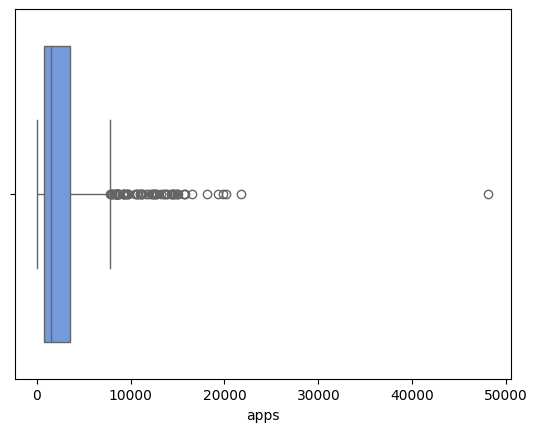

In [18]:
sns.boxplot(x=df['apps'], color='cornflowerblue')

In [19]:
df.shape

(748, 19)

In [20]:
df[df['apps']>30000]

,university,private,apps,accept,enroll,top10perc,top25perc,f_undergrad,p_undergrad,outstate,room_board,books,personal,phd,terminal,s_f_ratio,perc_alumni,expend,grad_rate
483,Rutgers at New Brunswick,0,48094,26330,4520,36,79,21401,3712,7410,4748,690,2009,90.0,95,19.5,19,10474,77


In [21]:
df.shape

(748, 19)

In [22]:
df_clean = df[df['apps']<30000]
df_clean.shape

(747, 19)

<Axes: >

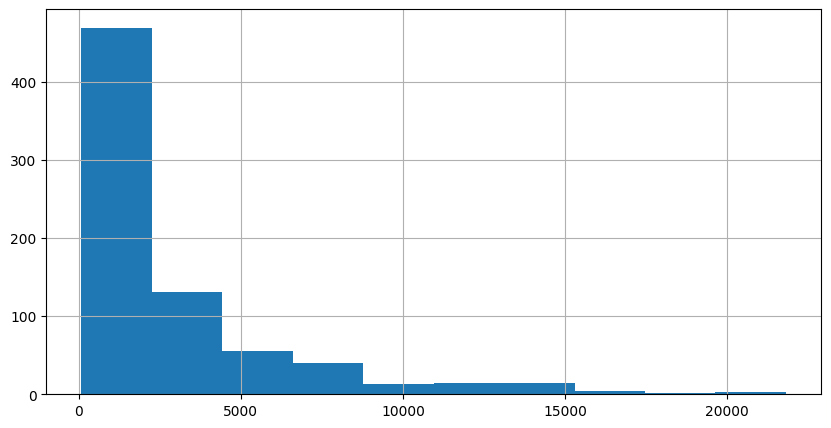

In [29]:
# We can make a decision to drop the outlier, if we want! Test it!
df_clean['apps'].hist(figsize=(10,5))

# EDA: What else do we want to explore?
---

In [31]:
sns.heatmap(
    data=df
    annot=True,
    vmin = -1,
    vmax = 1,
    cmap = 'coolwarm'
);

ValueError: could not convert string to float: 'Abilene Christian University'

In [ ]:
# phd & grad rate minimum


In [ ]:
# We can make a decision to drop the outlier, if we choose!


# EDA: Create Histograms of All Numerical Columns
---

# EDA: Plot a Heatmap of the Correlation Matrix
---

Heatmaps are an effective way to visually examine the correlational structure of your predictors.

##### What if I just wanted to look at the correlation to `apps`?

# EDA: Use seaborn's `.pairplot()` method to create scatterplots
---

Let's create a pairplot to see how some of our stronger predictors correlate to our target (`apps`). Instead of creating a pairplot of the entire DataFrame, we can use the `y_vars` and `x_vars` params to get a smaller subset.

# Model Prep: Create our features matrix (`X`) and target vector (`y`)
---

What should our features be?

The `apps` column is our label: the number of applications received by that university.

In the cell below, create your `X` and `y` variables.

# Model Prep: Train/test split
---

We always want to have a holdout set to test our model. Use the `train_test_split` function to split our `X` and `y` variables into a training set and a holdout set.

# Model Prep: Scaling
---

In the cell below, fit a `StandardScaler` to `X_train` and use it to transform both `X_train` and `X_test`. This is especially important when we learn about `Ridge` and `Lasso` next week!

# Model Prep: Instantiate our model
---


# Evaluation
---

Use `.score` to evaluate the model.

# LINE Assumptions
---


In [ ]:
# N - Normality of errors


In [ ]:
# E - Equal variance of errors
# Residual plot


> Variance of the dependent variable varies and is not constant across the entire dataset.

In [ ]:
 # What do we do? One option is to transform our dependent variable. A common transformation is to simply take the log of the dependent variable.

In [ ]:
# What did this just do?


## **Note**
> Logarithmic transformation is a convenient means of transforming a highly skewed variable into a more normalized dataset.

In [ ]:


# E - Equal variance of errors
# Residual plot


### 😔

## Let's say that this model DID actually perform better... what do I need to remember to do to make predictions?

In [ ]:
# You must use the exponential to "undo" our log transformation!
